# Pipeline de entrenamiento, validación y clasificador base

## Objetivo

Implementar un pipeline básico de clasificación utilizando PyTorch, que permita cargar y preparar un conjunto de datos, definir una arquitectura de red neuronal, entrenar el modelo y evaluar su rendimiento sobre un conjunto de validación independiente.

Para este desarrollo se utiliza el dataset Iris, un problema de clasificación multiclase.

El trabajo contempla la configuración del entorno de ejecución, la definición del modelo, la implementación del ciclo de entrenamiento y evaluación, y el análisis de las métricas obtenidas.

### **Configuración del entorno**

In [14]:
# Importar bibliotecas
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

# Configurar semilla para garantizar la reproducibilidad
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Detectar automáticamente el dispositivo disponible
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# Mostrar información del entorno de ejecución
print(f"Versión de PyTorch: {torch.__version__}")
print(f"Dispositivo utilizado: {device}")
print(f"Semilla aleatoria: {SEED}")

Versión de PyTorch: 2.11.0+cpu
Dispositivo utilizado: cpu
Semilla aleatoria: 42


### **Carga y exploración del conjunto de datos**

Se utiliza el dataset Iris, disponible en la biblioteca Scikit-learn. Contiene 150 observaciones de flores, caracterizadas mediante cuatro variables morfológicas: longitud y ancho del sépalo, y longitud y ancho del pétalo.

El objetivo es clasificar cada observación en una de las tres especies: *Iris setosa*, *Iris versicolor* e *Iris virginica*.

El conjunto de datos presenta una distribución equilibrada, con 50 observaciones por clase.

In [15]:
# Cargar el dataset Iris
iris = load_iris()

# Separar características y etiquetas
X = iris.data
y = iris.target

# Explorar la estructura del dataset
print(f"Dimensiones de las características: {X.shape}")
print(f"Dimensiones de las etiquetas: {y.shape}")
print(f"Nombres de las características: {iris.feature_names}")
print(f"Clases del problema: {iris.target_names}")
print(f"Distribución de las clases: {np.bincount(y)}")
print(f"Cantidad de observaciones: {X.shape[0]}")
print(f"Cantidad de características: {X.shape[1]}")

Dimensiones de las características: (150, 4)
Dimensiones de las etiquetas: (150,)
Nombres de las características: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Clases del problema: ['setosa' 'versicolor' 'virginica']
Distribución de las clases: [50 50 50]
Cantidad de observaciones: 150
Cantidad de características: 4


### **Preparación de los datos**

El dataset se divide en conjuntos de entrenamiento (80%) y validación (20%), utilizando estratificación para conservar la proporción de clases en ambos subconjuntos.

Las características se estandarizan mediante StandardScaler. Los parámetros de estandarización se calculan exclusivamente con los datos de entrenamiento y luego se aplican al conjunto de validación, evitando la fuga de información (*data leakage*).

Finalmente, las características y etiquetas se convierten a tensores de PyTorch, utilizando float32 para las variables predictoras y long para las etiquetas de clase. Los tensores se trasladan al dispositivo seleccionado para la ejecución.

In [16]:
# Dividir los datos en conjuntos de entrenamiento y validación
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Estandarizar las características utilizando únicamente la información del conjunto de entrenamiento
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

# Convertir las características a tensores float32
X_train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)

# Convertir las etiquetas a tensores long
y_train_tensor = torch.tensor(y_train, dtype=torch.long).to(device)
y_val_tensor = torch.tensor(y_val, dtype=torch.long).to(device)

# Verificar dimensiones, dispositivo y distribución de clases
print("Entrenamiento:", X_train_tensor.shape, y_train_tensor.shape)
print("Validación:", X_val_tensor.shape, y_val_tensor.shape)
print("Dispositivo de X_train:", X_train_tensor.device)
print("Dispositivo de y_train:", y_train_tensor.device)
print("Clases en entrenamiento:", np.bincount(y_train))
print("Clases en validación:", np.bincount(y_val))

Entrenamiento: torch.Size([120, 4]) torch.Size([120])
Validación: torch.Size([30, 4]) torch.Size([30])
Dispositivo de X_train: cpu
Dispositivo de y_train: cpu
Clases en entrenamiento: [40 40 40]
Clases en validación: [10 10 10]


### **Definición de la arquitectura del modelo**

Se implementa una red neuronal multicapa (Multilayer Perceptron, MLP) mediante la clase IrisClassifier, que hereda de nn.Module de PyTorch.

La arquitectura consta de una capa de entrada de cuatro características, una capa oculta de 16 neuronas con activación ReLU y una capa de salida de tres neuronas, correspondientes a las clases del dataset.

El modelo devuelve logits sin aplicar Softmax, ya que se utilizará CrossEntropyLoss como función de pérdida durante el entrenamiento.

In [17]:
# Definir la arquitectura de la red neuronal
class IrisClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()

        # Definir las capas de la red
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    # Definir la propagación hacia adelante
    def forward(self, x):
        return self.network(x)


# Definir las dimensiones de entrada, capa oculta y salida
input_dim = X_train_tensor.shape[1]
hidden_dim = 16
output_dim = len(iris.target_names)

# Crear el modelo y trasladarlo al dispositivo seleccionado
model = IrisClassifier(
    input_dim=input_dim,
    hidden_dim=hidden_dim,
    output_dim=output_dim
).to(device)

# Mostrar la arquitectura del modelo
print(model)

IrisClassifier(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=3, bias=True)
  )
)


### **Funciones de entrenamiento y evaluación**

Se implementan dos funciones para separar las etapas del pipeline:

- **Entrenamiento (`train_one_epoch`):** ejecuta una época de entrenamiento, calcula la pérdida, obtiene los gradientes mediante backpropagation y actualiza los parámetros del modelo utilizando el optimizador.
- **Evaluación (`evaluate`):** calcula la pérdida y la exactitud sobre los datos de validación, sin realizar actualizaciones de los parámetros.

Esta separación permite controlar y analizar el rendimiento del modelo durante el entrenamiento.

In [18]:
def train_one_epoch(model, X, y, criterion, optimizer):
    # Activar el modo de entrenamiento
    model.train()

    # Limpiar los gradientes acumulados
    optimizer.zero_grad()

    # Forward: propagación hacia adelante
    predictions = model(X)

    # Calcular la pérdida
    loss = criterion(predictions, y)

    # Backward: calcular los gradientes
    loss.backward()

    # Actualizar los parámetros del modelo
    optimizer.step()

    # Calcular la exactitud (accuracy)
    predicted_classes = predictions.argmax(dim=1)
    accuracy = (predicted_classes == y).float().mean().item()

    return loss.item(), accuracy

In [19]:
def evaluate(model, X, y, criterion):
    # Activar el modo de evaluación
    model.eval()

    # Desactivar el cálculo de gradientes
    with torch.no_grad():

        # Propagación hacia adelante
        predictions = model(X)

        # Calcular la pérdida
        loss = criterion(predictions, y)

        # Calcular la exactitud (accuracy)
        predicted_classes = predictions.argmax(dim=1)
        accuracy = (predicted_classes == y).float().mean().item()

    return loss.item(), accuracy

In [20]:
# Definir la función de pérdida para clasificación multiclase
criterion = nn.CrossEntropyLoss()

# Definir el optimizador Adam y la tasa de aprendizaje
optimizer = optim.Adam(model.parameters(), lr=0.01)

### **Configuración y ejecución del entrenamiento**

El modelo se entrena durante 100 épocas utilizando el optimizador Adam, con una tasa de aprendizaje de 0.01 y la función de pérdida CrossEntropyLoss.

En cada época se utilizan todas las observaciones del conjunto de entrenamiento para calcular la pérdida y actualizar los parámetros. Posteriormente, se evalúa el modelo sobre el conjunto de validación.

Las métricas de pérdida y exactitud (*accuracy*) se registran en cada época para analizar la evolución del proceso de aprendizaje.

In [21]:
# Definir la cantidad de épocas de entrenamiento
EPOCHS = 100

# Diccionario para guardar las métricas de cada época
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

# Bucle principal de entrenamiento
for epoch in range(EPOCHS):

    # Entrenamiento: actualizar los parámetros del modelo
    train_loss, train_accuracy = train_one_epoch(
        model,
        X_train_tensor,
        y_train_tensor,
        criterion,
        optimizer
    )

    # Validación: evaluar el modelo sin actualizar sus parámetros
    val_loss, val_accuracy = evaluate(
        model,
        X_val_tensor,
        y_val_tensor,
        criterion
    )

    # Guardar los resultados de esta época
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    # Mostrar las métricas
    print(
        f"Época {epoch + 1:03d}/{EPOCHS} | "
        f"Loss entrenamiento: {train_loss:.4f} | "
        f"Accuracy entrenamiento: {train_accuracy:.4f} | "
        f"Loss validación: {val_loss:.4f} | "
        f"Accuracy validación: {val_accuracy:.4f}"
    )

Época 001/100 | Loss entrenamiento: 1.0461 | Accuracy entrenamiento: 0.3667 | Loss validación: 0.9991 | Accuracy validación: 0.5333
Época 002/100 | Loss entrenamiento: 0.9977 | Accuracy entrenamiento: 0.4500 | Loss validación: 0.9543 | Accuracy validación: 0.6667
Época 003/100 | Loss entrenamiento: 0.9497 | Accuracy entrenamiento: 0.6167 | Loss validación: 0.9098 | Accuracy validación: 0.7333
Época 004/100 | Loss entrenamiento: 0.9023 | Accuracy entrenamiento: 0.7167 | Loss validación: 0.8657 | Accuracy validación: 0.7333
Época 005/100 | Loss entrenamiento: 0.8553 | Accuracy entrenamiento: 0.8417 | Loss validación: 0.8220 | Accuracy validación: 0.7333
Época 006/100 | Loss entrenamiento: 0.8090 | Accuracy entrenamiento: 0.8500 | Loss validación: 0.7794 | Accuracy validación: 0.7667
Época 007/100 | Loss entrenamiento: 0.7634 | Accuracy entrenamiento: 0.8583 | Loss validación: 0.7380 | Accuracy validación: 0.7667
Época 008/100 | Loss entrenamiento: 0.7190 | Accuracy entrenamiento: 0.8500 

### **Análisis de resultados**

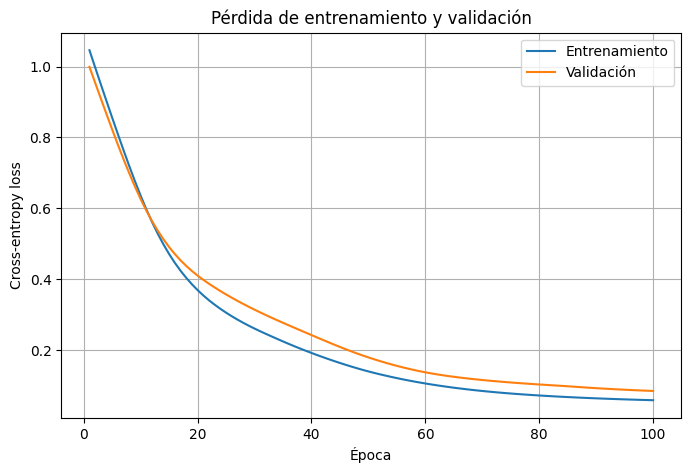

In [22]:
# Definir el rango de épocas
epochs_range = range(1, EPOCHS + 1)

# Graficar la evolución de la pérdida
plt.figure(figsize=(8, 5))

plt.plot(epochs_range, history["train_loss"], label="Entrenamiento")
plt.plot(epochs_range, history["val_loss"], label="Validación")

# Configurar el gráfico
plt.xlabel("Época")
plt.ylabel("Cross-entropy loss")
plt.title("Pérdida de entrenamiento y validación")
plt.legend()
plt.grid(True)

plt.show()


### Interpretación de la curva de pérdida

La pérdida (*loss*) disminuye progresivamente a lo largo de las 100 épocas, tanto en el conjunto de entrenamiento como en el de validación. En entrenamiento, desciende de 1.0461 a 0.0590, mientras que en validación disminuye de 0.9991 a 0.0851.

Esta evolución indica que el modelo mejora sus predicciones a medida que se actualizan sus parámetros. Ambas curvas mantienen una tendencia descendente, sin evidenciar divergencias crecientes, lo que sugiere un proceso de aprendizaje adecuado y sin signos marcados de sobreajuste durante el entrenamiento.

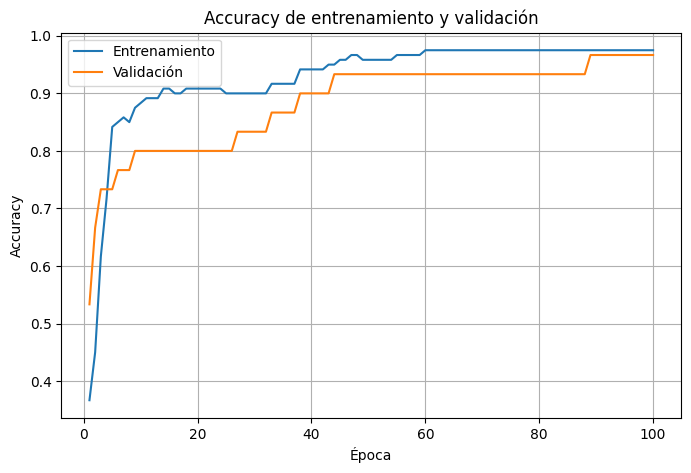

In [23]:
# Graficar la evolución de la exactitud (accuracy)
plt.figure(figsize=(8, 5))

plt.plot(epochs_range, history["train_accuracy"], label="Entrenamiento")
plt.plot(epochs_range, history["val_accuracy"], label="Validación")

# Configurar el gráfico
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.title("Accuracy de entrenamiento y validación")
plt.legend()
plt.grid(True)

plt.show()

### Interpretación de la curva de accuracy

La exactitud (*accuracy*) aumenta progresivamente durante el entrenamiento, alcanzando un valor final de 97.50% en el conjunto de entrenamiento y 96.67% en el conjunto de validación. Esto indica que el modelo logra clasificar correctamente la mayoría de las observaciones de ambos conjuntos.

La evolución de ambas curvas muestra un comportamiento similar, con una diferencia pequeña entre sus valores finales. Estos resultados sugieren que el modelo presenta un buen desempeño de clasificación y una adecuada capacidad de generalización sobre los datos de validación.